In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/orders_clean.csv", parse_dates=["order_datetime"])
df["line_total"] = df["amount"] * df["quantity"]

# تاریخ مرجع: یک روز بعد از آخرین سفارش داده
snapshot = df["order_datetime"].max() + pd.Timedelta(days=1)

last_order = df.groupby("customer_id")["order_datetime"].max()

rfm = pd.DataFrame({
    "recency": (snapshot - last_order).dt.days,
    "frequency": df.groupby("customer_id")["order_id"].nunique(),
    "monetary": df.groupby("customer_id")["line_total"].sum(),
})

print("تاریخ مرجع:", snapshot.date())
print("شکل جدول:", rfm.shape)
print("جمع monetary:", rfm["monetary"].sum())
rfm.describe().round(1)

تاریخ مرجع: 2018-12-12
شکل جدول: (151631, 3)
جمع monetary: 316021416421.0


,recency,frequency,monetary
count,151631.0,151631.0,1.516310e+05
mean,510.1,1.3,2.084148e+06
std,387.4,1.0,7.349063e+06
min,1.0,1.0,1.000000e+00
25%,210.0,1.0,1.900000e+05
50%,402.0,1.0,5.500000e+05
75%,748.0,1.0,1.650115e+06
max,1901.0,150.0,1.530359e+09


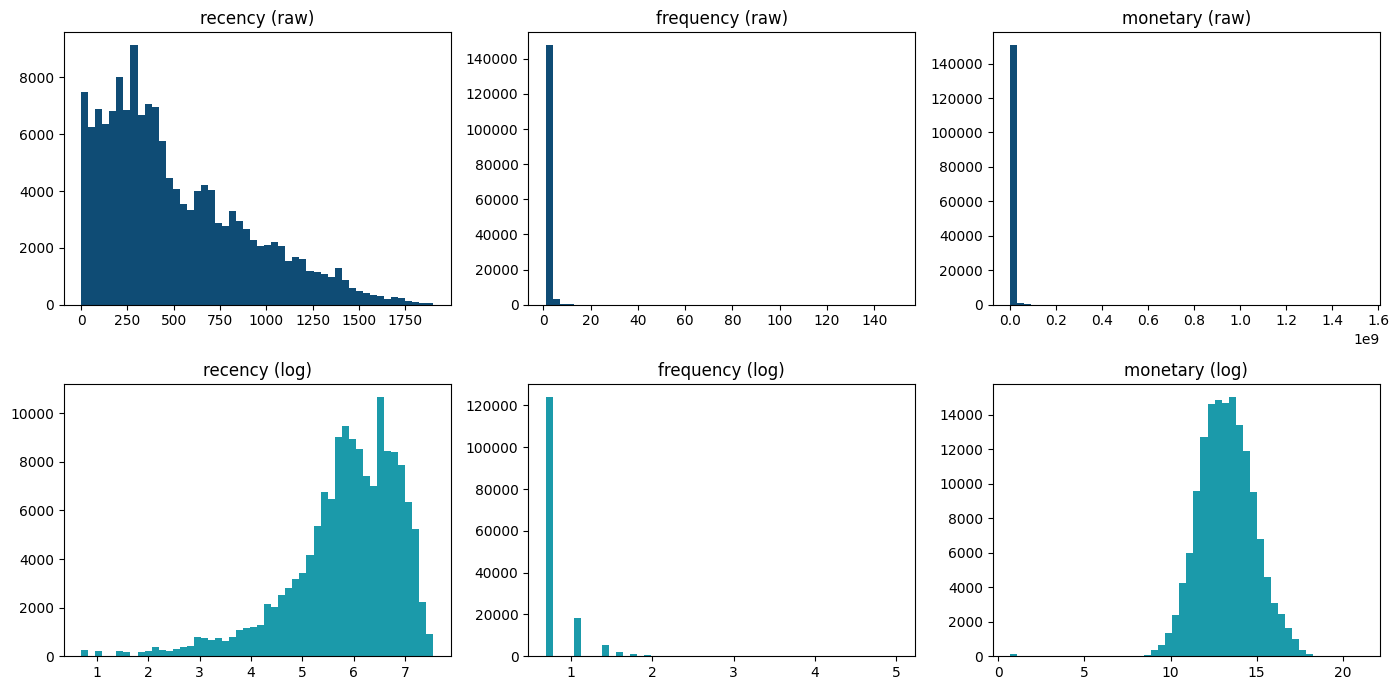

کجی قبل از لگاریتم:
recency       0.90
frequency    32.26
monetary     72.21
dtype: float64
کجی بعد از لگاریتم:
recency     -1.32
frequency    2.94
monetary    -0.30
dtype: float64


In [2]:
rfm_log = pd.DataFrame({
    "recency": np.log1p(rfm["recency"]),
    "frequency": np.log1p(rfm["frequency"]),
    "monetary": np.log1p(rfm["monetary"]),
})

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(["recency", "frequency", "monetary"]):
    axes[0, i].hist(rfm[col], bins=50, color="#0F4C75")
    axes[0, i].set_title(f"{col} (raw)")
    axes[1, i].hist(rfm_log[col], bins=50, color="#1B9AAA")
    axes[1, i].set_title(f"{col} (log)")
plt.tight_layout()
plt.savefig("../reports/figures/rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("کجی قبل از لگاریتم:")
print(rfm.skew().round(2))
print("کجی بعد از لگاریتم:")
print(rfm_log.skew().round(2))

In [3]:
from sklearn.preprocessing import StandardScaler

# recency خام، دو ستون دیگر با لگاریتم
features = pd.DataFrame({
    "recency": rfm["recency"],
    "frequency": np.log1p(rfm["frequency"]),
    "monetary": np.log1p(rfm["monetary"]),
})

print("کجی ستون‌ها:")
print(features.skew().round(2))

# هم‌مقیاس کردن
scaler = StandardScaler()
X = scaler.fit_transform(features)
X_df = pd.DataFrame(X, columns=features.columns, index=features.index)

print("میانگین بعد از مقیاس:")
print(X_df.mean().round(3))
print("پراکندگی بعد از مقیاس:")
print(X_df.std().round(3))

کجی ستون‌ها:
recency      0.90
frequency    2.94
monetary    -0.30
dtype: float64
میانگین بعد از مقیاس:
recency     -0.0
frequency    0.0
monetary    -0.0
dtype: float64
پراکندگی بعد از مقیاس:
recency      1.0
frequency    1.0
monetary     1.0
dtype: float64


k=2  inertia=321,824  silhouette=0.402
k=3  inertia=226,141  silhouette=0.374
k=4  inertia=171,989  silhouette=0.347
k=5  inertia=147,233  silhouette=0.347
k=6  inertia=123,780  silhouette=0.355
k=7  inertia=111,471  silhouette=0.317
k=8  inertia=101,026  silhouette=0.319


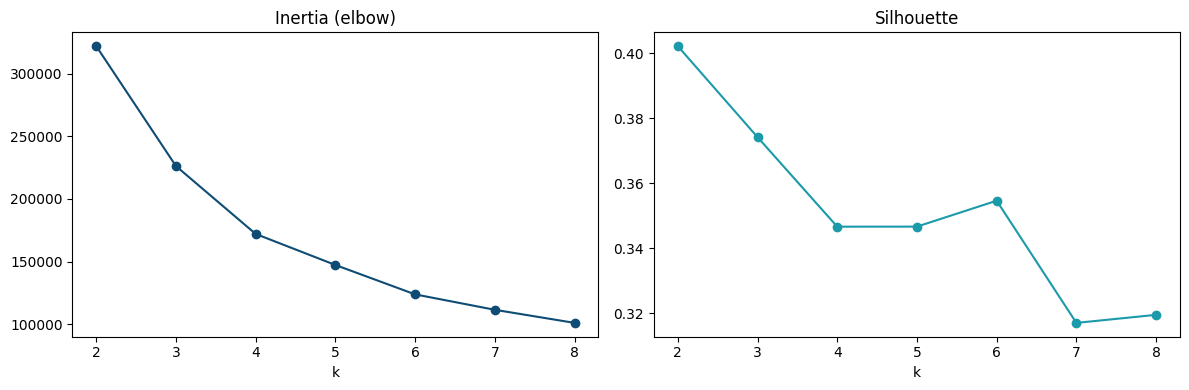

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    sil = silhouette_score(X, labels, sample_size=10000, random_state=42)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    print(f"k={k}  inertia={km.inertia_:,.0f}  silhouette={sil:.3f}")

res = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(res["k"], res["inertia"], marker="o", color="#0F4C75")
axes[0].set_title("Inertia (elbow)")
axes[0].set_xlabel("k")
axes[1].plot(res["k"], res["silhouette"], marker="o", color="#1B9AAA")
axes[1].set_title("Silhouette")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("../reports/figures/rfm_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

         customers  recency_median  frequency_mean  monetary_median  \
cluster                                                               
0            51432           322.0            1.01         167000.0   
1            33247          1060.0            1.04         504587.0   
2            25459           255.0            2.73        1315138.0   
3            41493           331.0            1.00        1547522.0   

         customers_pct  sales_pct  sales_billion  
cluster                                           
0                 33.9        3.2          10.13  
1                 21.9       17.3          54.61  
2                 16.8       30.0          94.87  
3                 27.4       49.5         156.41  
جمع فروش (میلیارد): 316.02


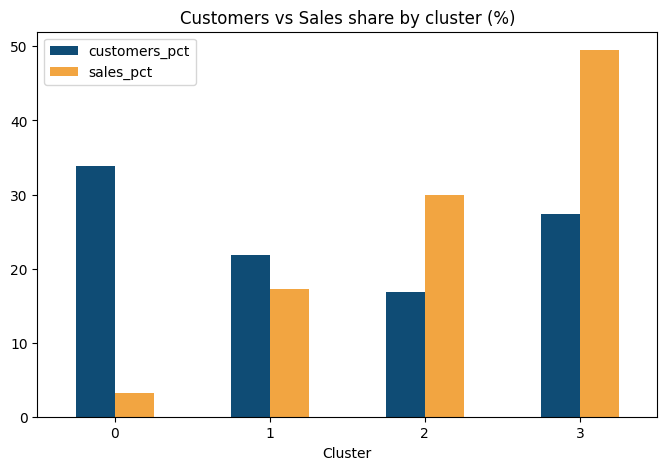

In [5]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm["cluster"] = km.fit_predict(X)

summary = rfm.groupby("cluster").agg(
    customers=("recency", "size"),
    recency_median=("recency", "median"),
    frequency_mean=("frequency", "mean"),
    monetary_median=("monetary", "median"),
    sales_total=("monetary", "sum"),
)
summary["customers_pct"] = (summary["customers"] / summary["customers"].sum() * 100).round(1)
summary["sales_pct"] = (summary["sales_total"] / summary["sales_total"].sum() * 100).round(1)
summary["frequency_mean"] = summary["frequency_mean"].round(2)
summary["sales_billion"] = (summary["sales_total"] / 1e9).round(2)
summary = summary.drop(columns="sales_total")
print(summary)
print("جمع فروش (میلیارد):", summary["sales_billion"].sum())

summary[["customers_pct", "sales_pct"]].plot(
    kind="bar", figsize=(8, 5), color=["#0F4C75", "#F2A541"]
)
plt.title("Customers vs Sales share by cluster (%)")
plt.xlabel("Cluster")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/rfm_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
summary[["customers", "recency_median", "frequency_mean", "monetary_median"]].round(1)

,customers,recency_median,frequency_mean,monetary_median
cluster,,,,
0,51432,322.0,1.0,167000.0
1,33247,1060.0,1.0,504587.0
2,25459,255.0,2.7,1315138.0
3,41493,331.0,1.0,1547522.0


# نتیجه‌ی بخش‌بندی مشتریان (RFM و K-Means)

**روش:** برای هر مشتری سه معیار ساخته شد: recency (روز از آخرین خرید تا ۱۲ آذر ۱۳۹۷)، frequency (تعداد سفارش یکتا) و monetary (جمع خرج). از frequency و monetary لگاریتم گرفته شد، سپس هر سه معیار هم‌مقیاس شدند. تعداد گروه‌ها با نمودار inertia و silhouette بررسی شد و k=4 انتخاب شد.

| گروه | اسم | مشتری | سهم فروش |
| --- | --- | --- | --- |
| 0 | تک‌خرید کم‌هزینه | ۳۳٫۹٪ | ۳٫۲٪ |
| 1 | مشتریان قدیمی | ۲۱٫۹٪ | ۱۷٫۳٪ |
| 2 | مشتریان تکراری | ۱۶٫۸٪ | ۳۰٫۰٪ |
| 3 | تک‌خرید پرهزینه | ۲۷٫۴٪ | ۴۹٫۵٪ |

**یافته‌ی اصلی:** گروه‌های ۲ و ۳ با ۴۴٪ مشتری‌ها حدود ۸۰٪ فروش را ساخته‌اند. گروه ۳ شامل ۲۷٪ مشتری‌ها و حدود نیمی از فروش است و فقط یک بار خرید کرده‌اند.

**محدودیت‌ها:**
- مقدار silhouette حدود ۰٫۳۵ است، یعنی گروه‌ها جدایی تیزی ندارند و مشتری‌ها بیشتر یک پیوستارند. این بخش‌بندی یک دسته‌بندی کاربردی است، نه کشف گروه‌های طبیعی.
- ۸۲٪ مشتری‌ها فقط یک بار خرید کرده‌اند، پس معیار frequency فقط گروه ۲ را جدا می‌کند.
- recency در سه گروه نزدیک هم است (۲۵۵ تا ۳۳۱ روز)؛ فقط گروه ۱ از نظر زمان جداست.
- واحد پول مشخص نیست و داده نمونه‌ای از تراکنش‌هاست، نه کل فروش دیجی‌کالا.